<a href="https://colab.research.google.com/github/ashycoding/NLP-LLM/blob/main/sentimentAnalysisNLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import kagglehub

# Download and load the Twitter sentiment dataset
path = kagglehub.dataset_download("shashankkumarranjan/twitter-sentiment")
print("Dataset downloaded to:", path)

# Dynamically locate the CSV file
files = os.listdir(path)
data_file = next((f for f in files if f.endswith('.csv')), None)

if data_file:
    file_path = os.path.join(path, data_file)
    df = pd.read_csv(file_path)
    print("First 5 records loaded:")
    display(df.head())
else:
    print("No CSV file found in the dataset directory.")

Using Colab cache for faster access to the 'twitter-sentiment' dataset.
Dataset downloaded to: /kaggle/input/twitter-sentiment
First 5 records loaded:


,clean_text,category
0,when modi promised “minimum government maximum...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0


### Exploratory Data Analysis (EDA)
We will analyze the dataset to understand its structure, check for missing values, and explore the distribution of both the sentiment categories and the text data.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset Info and Missing Values
print("--- Dataset Summary ---")
df.info()
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Drop rows with missing values for proper analysis if any exist
df_clean = df.dropna().copy()
print(f"\nShape before dropping NaNs: {df.shape}")
print(f"Shape after dropping NaNs: {df_clean.shape}")

--- Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162980 entries, 0 to 162979
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   clean_text  162976 non-null  object 
 1   category    162973 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.5+ MB

--- Missing Values ---
clean_text    4
category      7
dtype: int64

Shape before dropping NaNs: (162980, 2)
Shape after dropping NaNs: (162969, 2)


/tmp/ipykernel_5584/1853105709.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='category', palette='viridis')


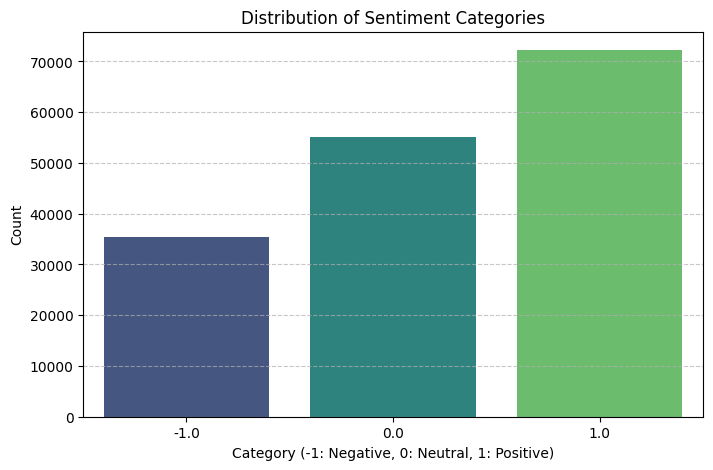


--- Category Proportions ---
category
 1.0    44.332971
 0.0    33.878222
-1.0    21.788806
Name: proportion, dtype: float64


In [3]:
# 2. Distribution of Sentiment Categories
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='category', palette='viridis')
plt.title('Distribution of Sentiment Categories')
plt.xlabel('Category (-1: Negative, 0: Neutral, 1: Positive)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Print proportion of categories
print("\n--- Category Proportions ---")
print(df_clean['category'].value_counts(normalize=True) * 100)

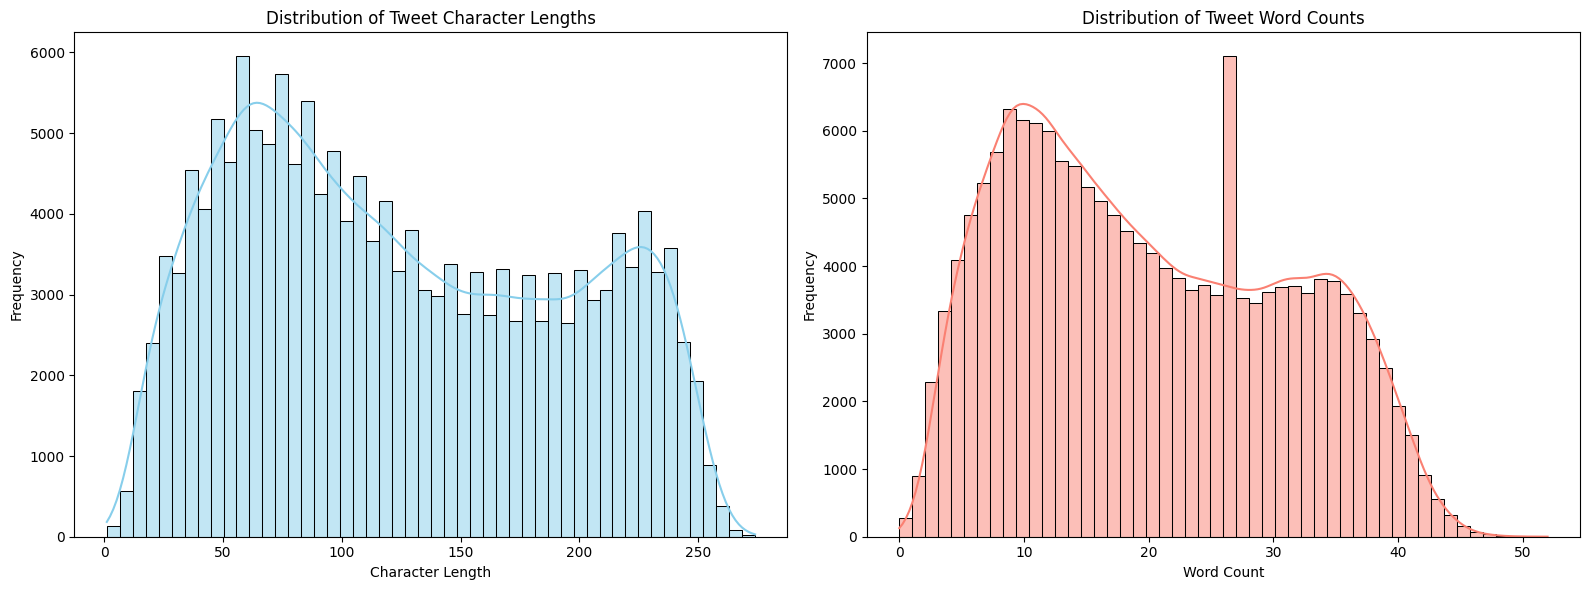


--- Text Statistics ---


,text_length,word_count
count,162969.000000,162969.000000
mean,124.178322,20.080702
std,67.924029,10.879596
min,1.000000,0.000000
25%,66.000000,11.000000
50%,114.000000,18.000000
75%,183.000000,29.000000
max,274.000000,52.000000


In [4]:
# 3. Text Length Analysis
# Calculate length (number of characters) and word count for each tweet
df_clean['text_length'] = df_clean['clean_text'].astype(str).apply(len)
df_clean['word_count'] = df_clean['clean_text'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution of Text Lengths
sns.histplot(df_clean['text_length'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Tweet Character Lengths')
axes[0].set_xlabel('Character Length')
axes[0].set_ylabel('Frequency')

# Distribution of Word Counts
sns.histplot(df_clean['word_count'], bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Tweet Word Counts')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print("\n--- Text Statistics ---")
display(df_clean[['text_length', 'word_count']].describe())

### Sentiment Analysis using Preloaded BERT Pipeline

Following the official Hugging Face documentation, we will use a preloaded transformer pipeline configured with a pre-trained BERT/RoBERTa model optimized specifically for Twitter sentiment analysis. This avoids training a neural network from scratch while leveraging state-of-the-art tokenization and model weights.

In [5]:
# Install necessary libraries
!pip install transformers datasets scipy

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from scipy.special import softmax
import numpy as np
import torch

# Check for GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load a pre-trained Twitter sentiment classifier model and tokenizer
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)

Using device: cpu


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### Tokenization Mechanics & Model Testing

To understand how the preloaded transformer interacts with our data, let's inspect the exact tokens produced by the tokenizer (including `[CLS]` and `[SEP]` boundaries or equivalent start/end of sequence tokens), their numeric IDs, and their corresponding attention masks. Then, we will test the model's classifications with distinct example inputs.

In [7]:
# 1. Inspect Tokenization Details on an Example Sentence
sample_sentence = "Twitter datasets are excellent for NLP sentiment analysis!"

# Convert text directly to tokens
tokens = tokenizer.tokenize(sample_sentence)
print("Tokens:", tokens)

# Encode text to extract input IDs and Attention Masks (which adds [CLS] and [SEP] boundaries)
inputs = tokenizer(sample_sentence, padding=True, truncation=True, max_length=15, return_tensors="pt")

# Map IDs back to their human-readable token labels to verify [CLS]/[SEP] placement
input_ids_list = inputs['input_ids'][0].tolist()
token_labels = tokenizer.convert_ids_to_tokens(input_ids_list)

print("\n--- Tokenization Encoding Breakdown ---")
print(f"{ 'Token Label':<20} | { 'Token ID':<10} | { 'Attention Mask':<15}")
print("-" * 53)
for label, token_id, mask in zip(token_labels, input_ids_list, inputs['attention_mask'][0].tolist()):
    print(f"{label:<20} | {token_id:<10} | {mask:<15}")

Tokens: ['Twitter', 'Ġdatasets', 'Ġare', 'Ġexcellent', 'Ġfor', 'ĠN', 'LP', 'Ġsentiment', 'Ġanalysis', '!']

--- Tokenization Encoding Breakdown ---
Token Label          | Token ID   | Attention Mask 
-----------------------------------------------------
<s>                  | 0          | 1              
Twitter              | 22838      | 1              
Ġdatasets            | 42532      | 1              
Ġare                 | 32         | 1              
Ġexcellent           | 4206       | 1              
Ġfor                 | 13         | 1              
ĠN                   | 234        | 1              
LP                   | 21992      | 1              
Ġsentiment           | 5702       | 1              
Ġanalysis            | 1966       | 1              
!                    | 328        | 1              
</s>                 | 2          | 1              


In [8]:
# 2. Define Sentiment Inference Function using the Preloaded Model
def analyze_tweet_sentiment(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128, padding=True).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    # Calculate Softmax probabilities
    probabilities = torch.nn.functional.softmax(outputs.logits, dim=-1)[0].cpu().numpy()
    labels = ['Negative', 'Neutral', 'Positive']
    max_idx = np.argmax(probabilities)

    return labels[max_idx], probabilities[max_idx], dict(zip(labels, probabilities))

# 3. Test with Diverse Examples
test_examples = [
    "I am so thrilled about our results today, outstanding job!",
    "This product is completely broken, extremely disappointed.",
    "We are scheduled to have a meeting tomorrow afternoon."
]

print("--- Model Prediction Testing ---")
for example in test_examples:
    pred_label, confidence, all_probs = analyze_tweet_sentiment(example)
    print(f"\nInput Text: \"{example}\"")
    print(f"Predicted Sentiment: {pred_label} (Confidence: {confidence:.4f})")
    print(f"All Class Probabilities: { {k: f'{v:.4f}' for k, v in all_probs.items()} }")

--- Model Prediction Testing ---

Input Text: "I am so thrilled about our results today, outstanding job!"
Predicted Sentiment: Positive (Confidence: 0.9887)
All Class Probabilities: {'Negative': '0.0047', 'Neutral': '0.0066', 'Positive': '0.9887'}

Input Text: "This product is completely broken, extremely disappointed."
Predicted Sentiment: Negative (Confidence: 0.9474)
All Class Probabilities: {'Negative': '0.9474', 'Neutral': '0.0446', 'Positive': '0.0080'}

Input Text: "We are scheduled to have a meeting tomorrow afternoon."
Predicted Sentiment: Neutral (Confidence: 0.9129)
All Class Probabilities: {'Negative': '0.0057', 'Neutral': '0.9129', 'Positive': '0.0814'}
